In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Initialize the Aer simulator
simulator = AerSimulator()
shots = 100

Original Bell-State Circuit:


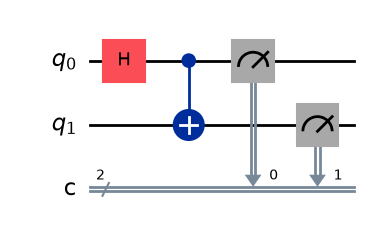

Original Counts: {'00': 51, '11': 49}


In [2]:
# Create a 2-qubit circuit with 2 classical bits
qc_original = QuantumCircuit(2, 2)
qc_original.h(0)
qc_original.cx(0, 1)
qc_original.measure([0, 1], [0, 1])

# Draw the original circuit
print("Original Bell-State Circuit:")
display(qc_original.draw('mpl'))

# Run the simulation for 100 shots
result_original = simulator.run(qc_original, shots=shots).result()
counts_original = result_original.get_counts()
print("Original Counts:", counts_original)

Modified Circuit:


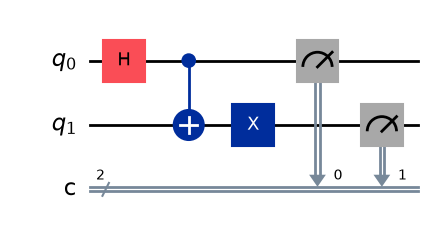

Modified Counts: {'10': 48, '01': 52}


In [3]:
# Create the modified 2-qubit circuit (3 gates total before measurement)
qc_modified = QuantumCircuit(2, 2)
qc_modified.h(0)
qc_modified.cx(0, 1)
qc_modified.x(1)  # Added 1 gate to flip the target qubit
qc_modified.measure([0, 1], [0, 1])

# Draw the modified circuit
print("Modified Circuit:")
display(qc_modified.draw('mpl'))

# Run the simulation for 100 shots
result_modified = simulator.run(qc_modified, shots=shots).result()
counts_modified = result_modified.get_counts()
print("Modified Counts:", counts_modified)

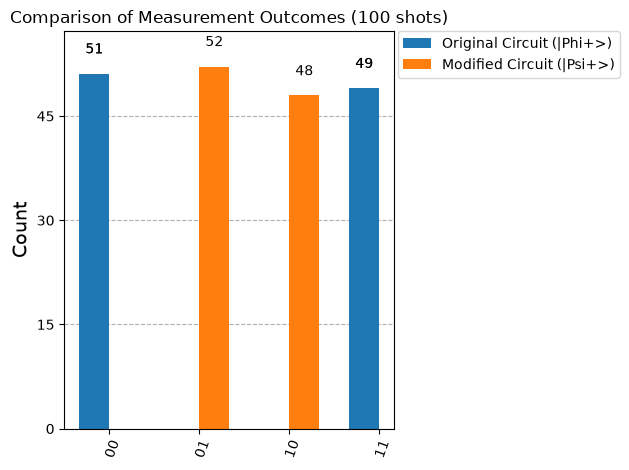

In [4]:
# Plot both results side-by-side for comparison
fig = plot_histogram(
    [counts_original, counts_modified],
    legend=['Original Circuit (|Phi+>)', 'Modified Circuit (|Psi+>)'],
    title="Comparison of Measurement Outcomes (100 shots)"
)
display(fig)